# Practice 1 — Bước 3: Đánh giá và Suy luận

Ở notebook này ta sẽ:
1. Nạp lại model tốt nhất từ `models/best_model.pth`.
2. Đánh giá trên **tập test 10.000 ảnh**: accuracy, precision/recall/F1 từng lớp,
   ma trận nhầm lẫn.
3. Xem các ảnh bị phân loại sai để hiểu điểm yếu của mô hình.
4. Suy luận 1 ảnh bất kỳ kèm phân phối xác suất.

**Điều kiện chạy:** đã huấn luyện xong ở `02_model_training.ipynb` (hoặc `python main.py`).

> Tài liệu liên quan: [`docs/evaluation.md`](../docs/evaluation.md) · [`docs/demo.md`](../docs/demo.md).

## 0. Chuẩn bị

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from src import config, data, evaluate, utils
from src.trainer import load_trained_model

utils.set_seed(config.SEED)
device = utils.get_device()
print('Thiết bị đánh giá:', device)

Thiết bị đánh giá: cuda


## 1. Nạp model tốt nhất

`load_trained_model` đọc checkpoint, khôi phục trọng số và in metadata
(epoch tốt nhất, val_loss/val_acc tại thời điểm lưu).

> Trọng số này được tạo ở [Bước 2](02_model_training.ipynb) — cấu hình 30 epoch + early stopping 5. Chi tiết: [`docs/training.md`](../docs/training.md).

In [2]:
model, checkpoint = load_trained_model(config.BEST_MODEL_PATH, device=device)
print('Epoch tốt nhất:', checkpoint['epoch'])
print('Val loss:', round(checkpoint['val_loss'], 4))
print('Val acc :', round(checkpoint['val_acc'], 4))

[trainer] Đã nạp model từ C:\Users\Admin\Downloads\Practice_11\models\best_model.pth (epoch 15, val_loss=0.1793, val_acc=0.9377)
Epoch tốt nhất: 15
Val loss: 0.1793
Val acc : 0.9377


## 2. Đánh giá trên tập test

Chạy dự đoán trên 10.000 ảnh test rồi tính:
- **Accuracy** — chỉ số chính (dữ liệu cân bằng lớp).
- **Precision / Recall / F1** từng lớp — xem lớp nào kém nhất.
- **Ma trận nhầm lẫn** — cặp lớp nào hay bị nhầm với nhau.

> Chi tiết các chỉ số & file lưu: [`docs/evaluation.md`](../docs/evaluation.md).

In [3]:
# Tập test giữ nguyên thứ tự, không augmentation
_, _, test_loader = data.get_dataloaders(use_augmentation=False)

y_true, y_pred = evaluate.collect_predictions(model, test_loader, device)
results = evaluate.evaluate_classification(y_true, y_pred)

[data] Nạp từ CSV:
  - train: fashion-mnist_train.csv
  - test : fashion-mnist_test.csv
[data] Số ảnh: train=54000, val=6000, test=10000 (batch_size=64, augmentation=tắt)


Dự đoán:   0%|          | 0/79 [00:00<?, ?it/s]

Accuracy trên tập đánh giá: 93.57%

              precision    recall  f1-score   support

 T-shirt/top     0.8758    0.9030    0.8892      1000
     Trouser     0.9910    0.9950    0.9930      1000
    Pullover     0.9409    0.8760    0.9073      1000
       Dress     0.9072    0.9680    0.9366      1000
        Coat     0.8912    0.9170    0.9039      1000
      Sandal     0.9949    0.9740    0.9843      1000
       Shirt     0.8381    0.7870    0.8118      1000
     Sneaker     0.9495    0.9780    0.9635      1000
         Bag     0.9930    0.9910    0.9920      1000
  Ankle boot     0.9758    0.9680    0.9719      1000

    accuracy                         0.9357     10000
   macro avg     0.9358    0.9357    0.9354     10000
weighted avg     0.9358    0.9357    0.9354     10000



## 3. Ma trận nhầm lẫn

Bản chuẩn hoá theo dòng cho biết **tỉ lệ** ảnh của một lớp bị dự đoán nhầm
sang lớp khác (tổng mỗi dòng = 1). Kết quả cũng được lưu ra
`outputs/tables/` và `outputs/figures/` bằng hàm `save_evaluation_results`.

> Diễn giải ma trận nhầm lẫn: [`docs/evaluation.md`](../docs/evaluation.md).

[utils] Đã lưu hình: C:\Users\Admin\Downloads\Practice_11\outputs\figures\03_confusion_matrix_test.png


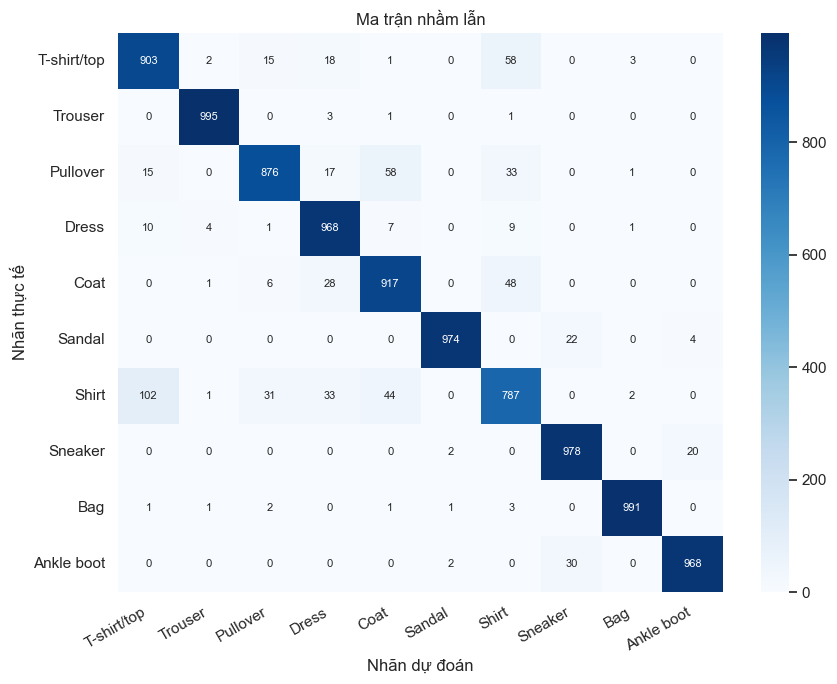

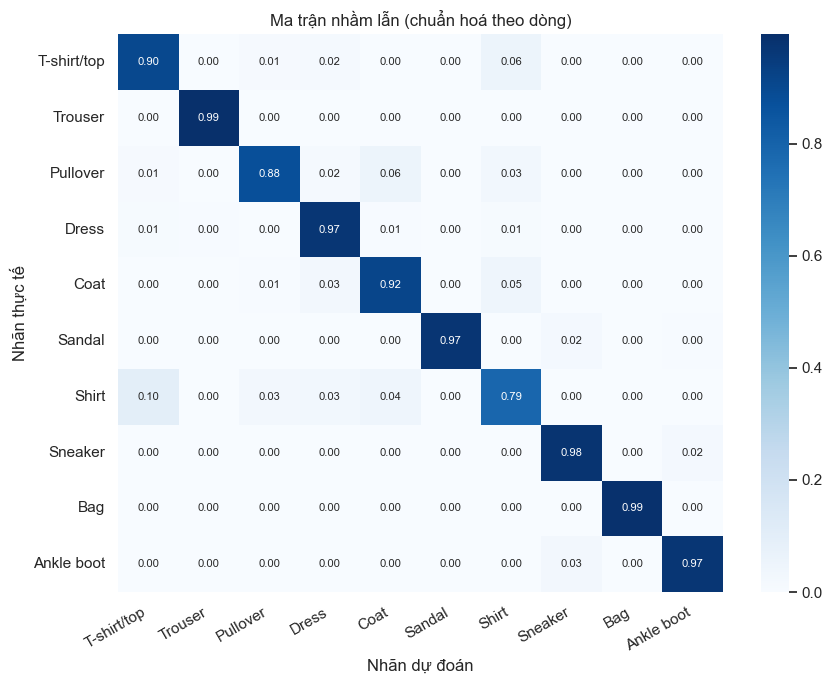

[utils] Đã lưu bảng: C:\Users\Admin\Downloads\Practice_11\outputs\tables\classification_report_test.csv
[utils] Đã lưu bảng: C:\Users\Admin\Downloads\Practice_11\outputs\tables\confusion_matrix_test.csv
[utils] Đã lưu hình: C:\Users\Admin\Downloads\Practice_11\outputs\figures\confusion_matrix_test.png
{'report': WindowsPath('C:/Users/Admin/Downloads/Practice_11/outputs/tables/classification_report_test.csv'), 'confusion_matrix': WindowsPath('C:/Users/Admin/Downloads/Practice_11/outputs/tables/confusion_matrix_test.csv'), 'figure': WindowsPath('C:/Users/Admin/Downloads/Practice_11/outputs/figures/confusion_matrix_test.png')}


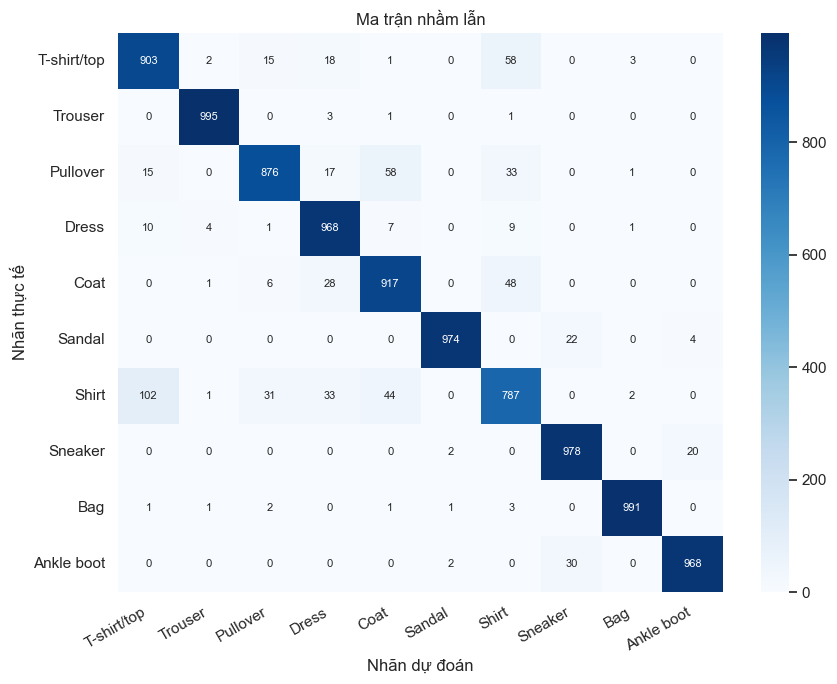

In [4]:
fig = utils.plot_confusion_matrix(results['confusion_matrix'], save_name='03_confusion_matrix_test')
plt.show()

fig = utils.plot_confusion_matrix(results['confusion_matrix'], normalize=True)
plt.show()

# Lưu 2 bảng CSV + hình PNG vào outputs/
paths = evaluate.save_evaluation_results(results, prefix='test')
print(paths)

## 4. Các ảnh bị phân loại sai

Mỗi ảnh có tiêu đề `T:` (nhãn thật) và `P:` (nhãn dự đoán).
Phần lớn lỗi thường nằm ở nhóm áo — *Shirt* bị nhầm với *T-shirt/top*,
*Pullover*, *Coat* — vì hình dạng và chất liệu trong ảnh xám rất gần nhau.

> Phân tích lỗi chi tiết: [`docs/evaluation.md`](../docs/evaluation.md).

Số ảnh sai lấy ra: 16
[utils] Đã lưu hình: C:\Users\Admin\Downloads\Practice_11\outputs\figures\03_misclassified.png


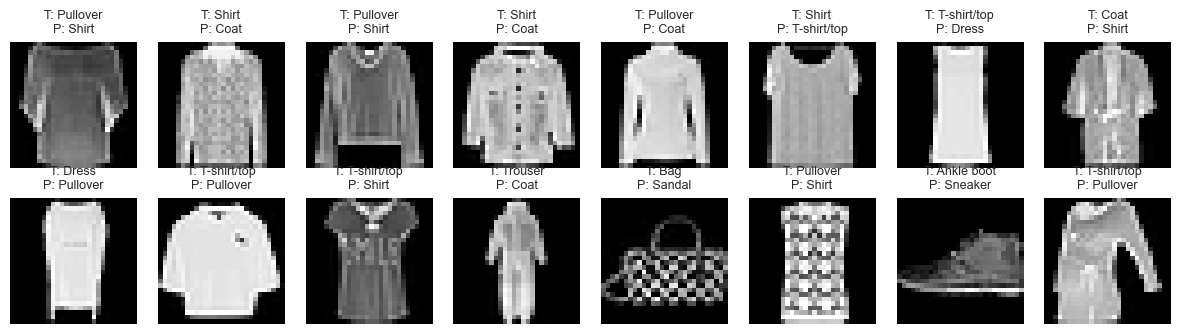

In [5]:
images, trues, preds = evaluate.get_misclassified(model, test_loader, device, max_samples=16)
titles = [
    f'T: {config.CLASS_NAMES[t]}\nP: {config.CLASS_NAMES[p]}'
    for t, p in zip(trues, preds)
]
print(f'Số ảnh sai lấy ra: {len(images)}')

fig = utils.plot_image_grid(images, titles, ncols=8, save_name='03_misclassified')
plt.show()

## 5. Suy luận 1 ảnh kèm phân phối xác suất

`predict_single` nhận ảnh thô (0–255 hoặc [0,1]), tự chuẩn hoá rồi trả về
nhãn dự đoán và xác suất của cả 10 lớp.

> Hướng dẫn suy luận ảnh ngoài: [`docs/demo.md`](../docs/demo.md).

[data] Nạp từ CSV:
  - train: fashion-mnist_train.csv
  - test : fashion-mnist_test.csv
Ảnh test thứ 7270
Nhãn thật  : Sneaker
Dự đoán    : Sneaker (xác suất 99.93%)
[utils] Đã lưu hình: C:\Users\Admin\Downloads\Practice_11\outputs\figures\03_prediction_example.png


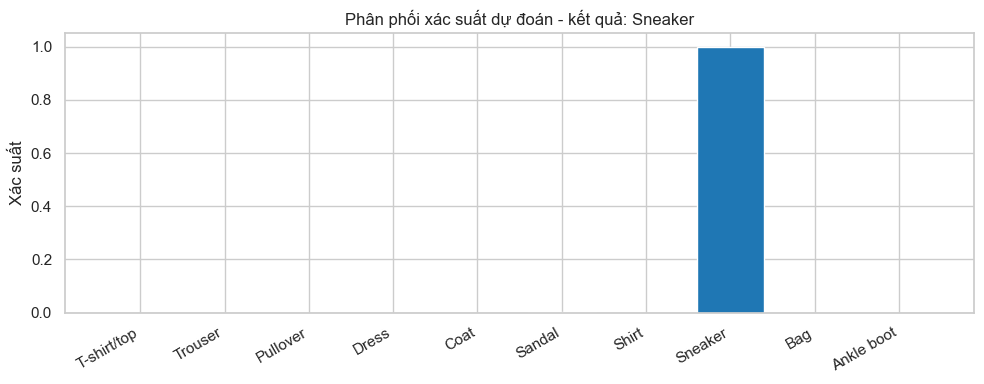

In [6]:
X_train, y_train, X_test, y_test = data.load_raw_arrays()

i = np.random.randint(len(X_test))
image01 = X_test[i] / 255.0  # về khoảng [0, 1]

pred_idx, pred_name, probs = evaluate.predict_single(model, image01, device)
print(f'Ảnh test thứ {i}')
print(f'Nhãn thật  : {config.CLASS_NAMES[y_test[i]]}')
print(f'Dự đoán    : {pred_name} (xác suất {probs[pred_idx]:.2%})')

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(config.CLASS_NAMES, probs, color='tab:blue')
ax.set_xticks(range(len(config.CLASS_NAMES)))
ax.set_xticklabels(config.CLASS_NAMES, rotation=30, ha='right')
ax.set_ylabel('Xác suất')
ax.set_title(f'Phân phối xác suất dự đoán - kết quả: {pred_name}')
fig.tight_layout()
utils.save_figure(fig, '03_prediction_example')
plt.show()

## 6. Tổng kết

- Đã hoàn thành pipeline end-to-end: **dữ liệu → huấn luyện → đánh giá → suy luận**.
- Accuracy tập test thường đạt khoảng **92–93%** với kiến trúc CNN này.
- Lớp **Shirt** có F1 thấp nhất do nhầm nhiều với *T-shirt/top*, *Pullover*, *Coat*.
- Hướng cải thiện: augmentation mạnh hơn, scheduler cosine, kiến trúc sâu hơn
  (ResNet cần resize ảnh lên 224×224), hoặc tăng epoch khi có GPU.

> Xem thêm [`docs/README.md`](../docs/README.md) để điều hướng toàn bộ tài liệu.